# 01 · SCIN exploratory data analysis

Phase 1 of the skin-condition triage project. This notebook answers:

1. How many cases and images are there?
2. How many cases have a usable dermatologist condition label?
3. Which conditions are common?
4. How are skin tones distributed (estimated Fitzpatrick and Monk)?
5. How do the common conditions spread across skin tones?
6. What do the image files look like (size, format)?

**Vocabulary.** A SCIN *case* is one contribution from one person, with 1–3 photos.
SCIN has no separate contributor ID, so the case is the unit we will split on.

Every number below is computed from the CSVs in `data/raw/scin/` (run `python -m src.download_scin --config configs/data.yaml` first).
Nothing here picks the final labels; that is Phase 2.

In [1]:
import os, sys
from pathlib import Path

# Work from the repo root so the config's relative paths resolve
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

from src.data import add_eda_columns, image_table, load_scin
from src.utils import load_config

CONFIG_PATH = "configs/data.yaml"
cfg = load_config(CONFIG_PATH)
RAW_DIR = Path(cfg["paths"]["raw_dir"])
FIG_DIR = Path("docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#52514e"
BLUES = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#86b6ef", "#2a78d6", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": INK, "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_rows", 60)

df = add_eda_columns(load_scin(RAW_DIR))
images = image_table(df)
print(f"Loaded {len(df):,} cases from {RAW_DIR}")

Loaded 5,033 cases from data/raw/scin


## 1. Cases and images

In [2]:
print(f"Cases:                     {len(df):,}")
print(f"Images referenced in CSV:  {len(images):,}")
print(f"Unique image paths:        {images.image_path.nunique():,}")
print(f"Mean images per case:      {df.n_images.mean():.2f}")

pd.DataFrame({
    "cases": df.n_images.value_counts().sort_index(),
}).rename_axis("images per case")

Cases:                     5,033
Images referenced in CSV:  10,407
Unique image paths:        10,380
Mean images per case:      2.07


,cases
images per case,
1,1948
2,796
3,2289


In [3]:
images.shot_type.value_counts(dropna=False).rename("images").to_frame()

,images
shot_type,
CLOSE_UP,5029
AT_AN_ANGLE,3015
AT_DISTANCE,2363


SCIN's README lists two known file issues: 15 images are duplicates (42 occurrences in total), and 1 image file is missing from the bucket.
The duplicates show up here as the same image path used by **more than one case**. That matters for splitting:
if two cases share a photo and land in different splits, the test set leaks into training.

In [4]:
cases_per_path = images.groupby("image_path").case_id.nunique()
shared_paths = cases_per_path[cases_per_path > 1]
shared_cases = images[images.image_path.isin(shared_paths.index)].case_id.unique()
print(f"Image paths used by more than one case: {len(shared_paths)}")
print(f"Total references to those paths:       {int(images.image_path.isin(shared_paths.index).sum())}")
print(f"Cases involved:                        {len(shared_cases)}")

Image paths used by more than one case: 15
Total references to those paths:       42
Cases involved:                        29


## 2. Which cases have a usable condition label?

Each case was reviewed by 1–3 dermatologists. Each reviewer first says whether the condition can be judged from the photos (*gradable*),
then lists up to 3 possible conditions with a confidence. SCIN combines these into `weighted_skin_condition_label`, e.g. `{'Eczema': 0.69, 'Psoriasis': 0.31}`.

For a single-label classifier we need one condition per case. The default used here: the **primary condition** is the top-weighted one.
If two conditions tie for the top weight, there is no single clear answer, so the case is flagged as *tied*.

In [5]:
labelled = df.n_conditions > 0
clear = labelled & df.gradable & ~df.primary_tied

steps = {
    "All cases": pd.Series(True, index=df.index),
    "Gradable by at least one dermatologist": df.gradable,
    "Has a condition label": labelled,
    "Gradable and labelled": df.gradable & labelled,
    "... with a single clear top condition (no tie)": clear,
    "... and top weight >= 0.5": clear & (df.primary_weight >= 0.5),
}
funnel = pd.DataFrame({
    "cases": {k: int(m.sum()) for k, m in steps.items()},
    "images": {k: int(df.loc[m, "n_images"].sum()) for k, m in steps.items()},
})
funnel["% of cases"] = (100 * funnel.cases / len(df)).round(1)
funnel

,cases,images,% of cases
All cases,5033,10407,100.0
Gradable by at least one dermatologist,3109,6615,61.8
Has a condition label,3061,6518,60.8
Gradable and labelled,3061,6518,60.8
... with a single clear top condition (no tie),2136,4566,42.4
... and top weight >= 0.5,1931,4003,38.4


In [6]:
print("Gradable but no condition label (SCIN known issue, expected 48):", int((df.gradable & ~labelled).sum()))
print("Labelled but not marked gradable:", int((~df.gradable & labelled).sum()))
print("Cases with a tied top condition:", int((labelled & df.primary_tied).sum()))

Gradable but no condition label (SCIN known issue, expected 48): 48
Labelled but not marked gradable: 0
Cases with a tied top condition: 925


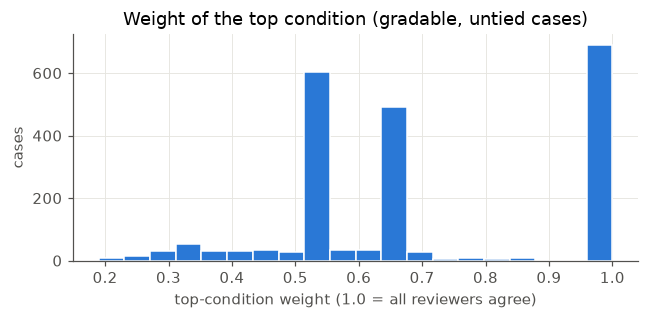

In [7]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(df.loc[df.gradable & labelled & ~df.primary_tied, "primary_weight"], bins=20, color=BLUE, edgecolor="white", linewidth=1)
ax.set(title="Weight of the top condition (gradable, untied cases)", xlabel="top-condition weight (1.0 = all reviewers agree)", ylabel="cases")
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_primary_weight.png"); plt.show()

### Missing values per field

How often each label or demographic field is missing, over all cases.

In [8]:
missing = pd.Series({
    "condition label (weighted)": (~labelled).mean(),
    "estimated Fitzpatrick (dermatologist)": df.efst.isna().mean(),
    "Monk skin tone (US graders)": df.monk_us.isna().mean(),
    "Monk skin tone (India graders)": df.monk_india.isna().mean(),
    "self-reported Fitzpatrick": (~df.fitzpatrick_skin_type.astype(str).str.match(r"FST\d")).mean(),
    "age group": df.age_group.isna().mean(),
    "sex at birth": df.sex_at_birth.isna().mean(),
})
(100 * missing).round(1).rename("% of cases missing").to_frame()

,% of cases missing
condition label (weighted),39.2
estimated Fitzpatrick (dermatologist),13.2
Monk skin tone (US graders),0.6
Monk skin tone (India graders),0.3
self-reported Fitzpatrick,56.8
age group,0.0
sex at birth,0.0


## 3. Condition counts

Counted over **usable cases**: gradable, labelled, and with a single clear top condition.
`cases mentioning` counts any case where the condition appears anywhere in the weighted label (not only on top), to show how often conditions co-occur in a differential.

In [9]:
usable = df[clear].copy()

mentions = (df.loc[labelled, "weighted_skin_condition_label"]
            .map(lambda s: list(eval(s).keys())).explode().value_counts())

counts = (usable.groupby("primary_condition")
          .agg(cases=("case_id", "size"), images=("n_images", "sum"),
               median_weight=("primary_weight", "median"),
               cases_weight_ge_05=("primary_weight", lambda w: int((w >= 0.5).sum())))
          .sort_values("cases", ascending=False))
counts["cases_mentioning"] = mentions.reindex(counts.index).astype(int)
print(f"Distinct primary conditions among usable cases: {len(counts)}")
counts.head(25)

Distinct primary conditions among usable cases: 177


,cases,images,median_weight,cases_weight_ge_05,cases_mentioning
primary_condition,,,,,
Eczema,368,828,0.67,324,1056
Allergic Contact Dermatitis,224,491,0.57,199,873
Urticaria,175,359,0.86,168,332
Insect Bite,134,300,0.55,123,403
Folliculitis,92,204,0.67,86,268
Psoriasis,65,135,0.55,55,308
Tinea,60,136,0.55,55,206
Herpes Simplex,54,108,0.67,51,141
Acne,45,91,0.67,43,98


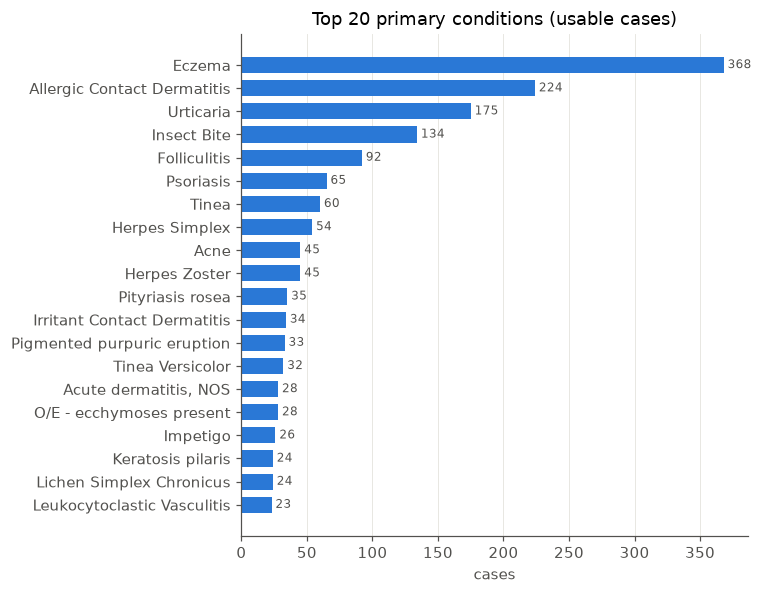

In [10]:
top20 = counts.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top20.index, top20.cases, color=BLUE, height=0.7)
for y, v in enumerate(top20.cases):
    ax.text(v + 3, y, str(v), va="center", fontsize=8, color=INK)
ax.set(title="Top 20 primary conditions (usable cases)", xlabel="cases")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_condition_counts.png"); plt.show()

## 4. Skin-tone distributions

SCIN provides three kinds of skin-tone information:

- **Self-reported Fitzpatrick (sFST)**: from the contributor's answers about tanning. Often missing.
- **Estimated Fitzpatrick (eFST)**: from dermatologists looking at the photos. Up to 3 labels per case; here combined as the median, rounded half up.
- **Estimated Monk skin tone (eMST)**: a 10-point scale, labelled separately by trained lay graders in the **US** and in **India**.

The brief asks for the dermatologist eFST and the Monk labels. sFST is shown for context only.

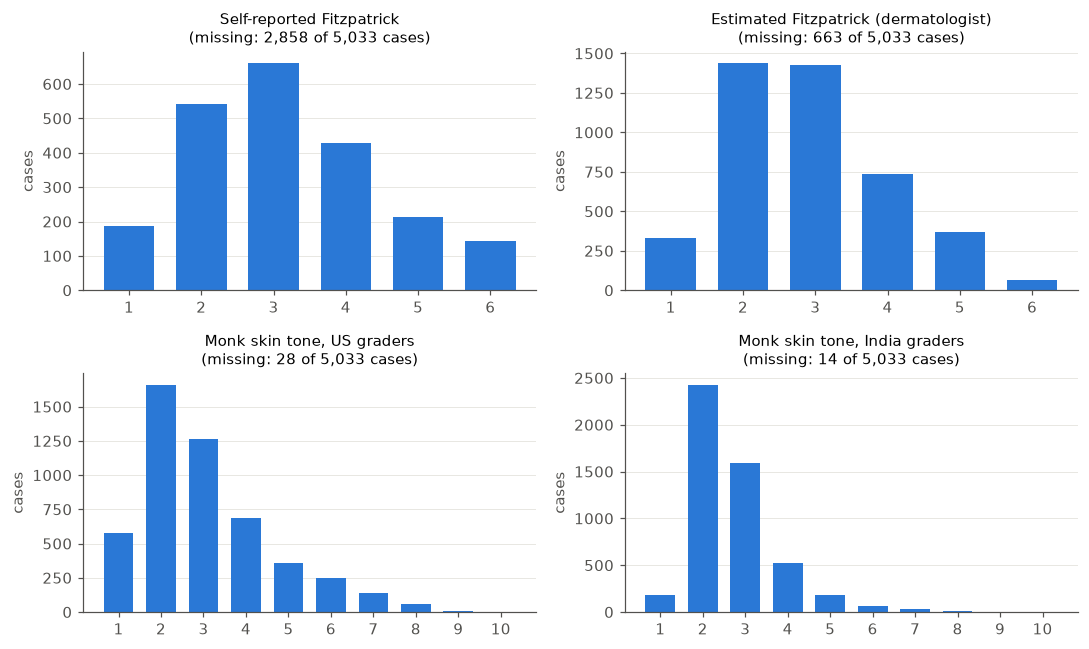

In [11]:
sfst = df.fitzpatrick_skin_type.map(lambda v: int(v[3:]) if isinstance(v, str) and v.startswith("FST") else np.nan)
panels = [
    ("Self-reported Fitzpatrick", sfst, range(1, 7)),
    ("Estimated Fitzpatrick (dermatologist)", df.efst, range(1, 7)),
    ("Monk skin tone, US graders", df.monk_us, range(1, 11)),
    ("Monk skin tone, India graders", df.monk_india, range(1, 11)),
]
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, (title, s, levels) in zip(axes.flat, panels):
    vc = s.value_counts().reindex(levels, fill_value=0)
    ax.bar([str(l) for l in levels], vc.values, color=BLUE, width=0.7)
    ax.set_title(f"{title}\n(missing: {s.isna().sum():,} of {len(s):,} cases)", fontsize=10)
    ax.set_ylabel("cases"); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_skin_tone_distributions.png"); plt.show()

In [12]:
tone_table = pd.DataFrame({
    "eFST cases": df.efst.value_counts().sort_index(),
    "eFST %": (100 * df.efst.value_counts(normalize=True).sort_index()).round(1),
}).rename_axis("Fitzpatrick type")
tone_table

,eFST cases,eFST %
Fitzpatrick type,,
1.0,334,7.6
2.0,1439,32.9
3.0,1424,32.6
4.0,737,16.9
5.0,368,8.4
6.0,68,1.6


In [13]:
monk_table = pd.DataFrame({
    "Monk US": df.monk_us.value_counts().reindex(range(1, 11), fill_value=0),
    "Monk India": df.monk_india.value_counts().reindex(range(1, 11), fill_value=0),
}).rename_axis("Monk tone")
monk_table

,Monk US,Monk India
Monk tone,,
1,577,187
2,1660,2427
3,1265,1591
4,687,522
5,361,177
6,248,63
7,137,35
8,57,14
9,11,3


### How much do labellers agree?

If labellers often disagree, skin-tone groups are noisy, and per-group results need to be read with that in mind.

In [14]:
efst_cols = [c for c in df.columns if c.startswith("dermatologist_fitzpatrick_skin_type_label_")]
efst_ints = df[efst_cols].apply(lambda col: col.map(lambda v: int(v[3:]) if isinstance(v, str) and v.startswith("FST") else np.nan))
multi = efst_ints.notna().sum(axis=1) >= 2
spread = (efst_ints.max(axis=1) - efst_ints.min(axis=1))[multi]
print(f"Cases with 2+ dermatologist eFST labels: {multi.sum():,}")
print(f"  all labels identical:      {100 * (spread == 0).mean():.1f}%")
print(f"  labels within 1 type:      {100 * (spread <= 1).mean():.1f}%")

both = df.monk_us.notna() & df.monk_india.notna()
diff = (df.monk_us - df.monk_india)[both]
print(f"\nCases with both US and India Monk labels: {both.sum():,}")
print(f"  identical:                 {100 * (diff == 0).mean():.1f}%")
print(f"  within 1 step:             {100 * (diff.abs() <= 1).mean():.1f}%")
print(f"  mean (US - India):         {diff.mean():+.2f} steps")

Cases with 2+ dermatologist eFST labels: 663
  all labels identical:      24.9%
  labels within 1 type:      73.9%

Cases with both US and India Monk labels: 5,004
  identical:                 40.1%
  within 1 step:             83.6%
  mean (US - India):         +0.35 steps


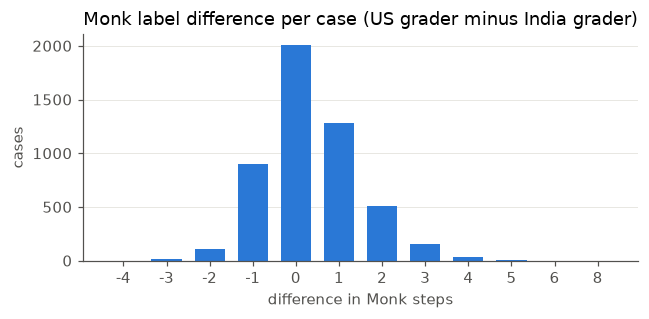

In [15]:
fig, ax = plt.subplots(figsize=(6, 3))
vc = diff.value_counts().sort_index()
ax.bar(vc.index.astype(int).astype(str), vc.values, color=BLUE, width=0.7)
ax.set(title="Monk label difference per case (US grader minus India grader)", xlabel="difference in Monk steps", ylabel="cases")
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_monk_us_vs_india.png"); plt.show()

In [16]:
pd.crosstab(df.efst, df.monk_us_group, margins=True).rename_axis(index="eFST", columns="Monk (US)")

Monk (US),Monk 1-3,Monk 4-6,Monk 7-10,All
eFST,,,,
1.0,315,17,1,333
2.0,1296,139,0,1435
3.0,1066,347,7,1420
4.0,321,391,23,735
5.0,38,223,107,368
6.0,0,13,55,68
All,3036,1130,193,4359


## 5. How common conditions spread across skin tones

For fairness analysis we need each class to have cases in every skin-tone group, ideally in the test set too.
Groups used here (a common convention, to be confirmed in Phase 2): **FST I–II, III–IV, V–VI** and **Monk 1–3, 4–6, 7–10**.

Shown for the 12 most common primary conditions among usable cases.

In [17]:
candidates = counts.head(12).index.tolist()
cand = usable[usable.primary_condition.isin(candidates)]

def by_group(col, order):
    t = pd.crosstab(cand.primary_condition, cand[col].fillna("missing"))
    t = t.reindex(columns=order + ["missing"], fill_value=0).reindex(candidates)
    t["total"] = t.sum(axis=1)
    return t

fst_order = ["FST I-II", "FST III-IV", "FST V-VI"]
monk_order = ["Monk 1-3", "Monk 4-6", "Monk 7-10"]
fst_by_cond = by_group("efst_group", fst_order)
monk_by_cond = by_group("monk_us_group", monk_order)
fst_by_cond["% V-VI (of known)"] = (100 * fst_by_cond["FST V-VI"] / fst_by_cond[fst_order].sum(axis=1)).round(1)
fst_by_cond

efst_group,FST I-II,FST III-IV,FST V-VI,missing,total,% V-VI (of known)
primary_condition,,,,,,
Eczema,166,152,37,13,368,10.4
Allergic Contact Dermatitis,99,105,10,10,224,4.7
Urticaria,64,88,11,12,175,6.7
Insect Bite,70,55,3,6,134,2.3
Folliculitis,34,53,4,1,92,4.4
Psoriasis,23,35,3,4,65,4.9
Tinea,25,27,5,3,60,8.8
Herpes Simplex,22,24,4,4,54,8.0
Acne,17,24,4,0,45,8.9


In [18]:
monk_by_cond["% 7-10 (of known)"] = (100 * monk_by_cond["Monk 7-10"] / monk_by_cond[monk_order].sum(axis=1)).round(1)
monk_by_cond

monk_us_group,Monk 1-3,Monk 4-6,Monk 7-10,missing,total,% 7-10 (of known)
primary_condition,,,,,,
Eczema,253,92,22,1,368,6.0
Allergic Contact Dermatitis,178,40,5,1,224,2.2
Urticaria,115,58,2,0,175,1.1
Insect Bite,107,25,1,1,134,0.8
Folliculitis,66,25,1,0,92,1.1
Psoriasis,41,21,2,1,65,3.1
Tinea,39,20,1,0,60,1.7
Herpes Simplex,31,20,2,1,54,3.8
Acne,30,15,0,0,45,0.0


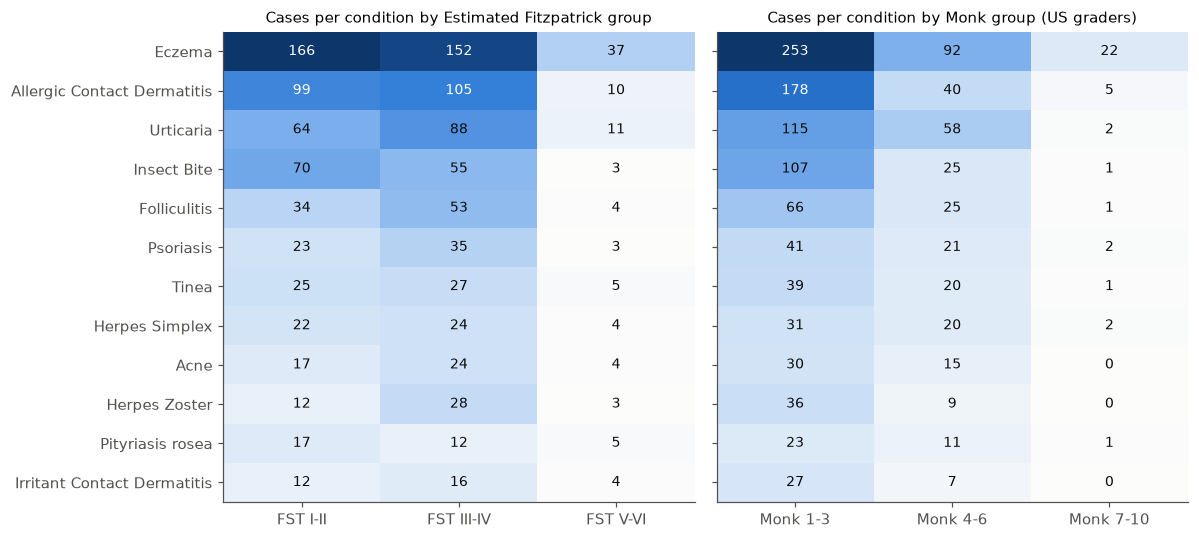

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, table, order, title in [(axes[0], fst_by_cond, fst_order, "Estimated Fitzpatrick group"),
                                (axes[1], monk_by_cond, monk_order, "Monk group (US graders)")]:
    m = table[order].values
    ax.imshow(m, cmap=BLUES, aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, m[i, j], ha="center", va="center", fontsize=9,
                    color="white" if m[i, j] > m.max() * 0.55 else "#0b0b0b")
    ax.set_xticks(range(len(order)), order); ax.set_yticks(range(len(candidates)), candidates)
    ax.set_title(f"Cases per condition by {title}", fontsize=10); ax.grid(False)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_condition_by_skin_tone.png"); plt.show()

**Why this matters for the test set.** With a case-level split of roughly 70/15/15, a condition with *n* cases in a skin-tone group
gets about 0.15 × *n* of them in the test set. The table below shows that expected count for the darkest groups.

In [20]:
expected_test = pd.DataFrame({
    "FST V-VI cases": fst_by_cond["FST V-VI"],
    "expected in 15% test": (0.15 * fst_by_cond["FST V-VI"]).round(1),
    "Monk 7-10 cases": monk_by_cond["Monk 7-10"],
    "expected in 15% test ": (0.15 * monk_by_cond["Monk 7-10"]).round(1),
})
expected_test

,FST V-VI cases,expected in 15% test,Monk 7-10 cases,expected in 15% test
primary_condition,,,,
Eczema,37,5.6,22,3.3
Allergic Contact Dermatitis,10,1.5,5,0.8
Urticaria,11,1.6,2,0.3
Insect Bite,3,0.4,1,0.2
Folliculitis,4,0.6,1,0.2
Psoriasis,3,0.4,2,0.3
Tinea,5,0.8,1,0.2
Herpes Simplex,4,0.6,2,0.3
Acne,4,0.6,0,0.0


## 6. Image sizes

Measured on the image files present locally. On a laptop this is the seeded random sample downloaded with `images: sample`;
with `--images all` (e.g. on Kaggle/Colab) it covers every image.

In [21]:
local = images[images.image_path.map(lambda p: (RAW_DIR / p).exists())].copy()

def read_header(path):
    with Image.open(RAW_DIR / path) as im:  # reads the header only
        return im.width, im.height, im.format, im.mode

local[["width", "height", "format", "mode"]] = local.image_path.map(read_header).tolist()
local[["width", "height"]] = local[["width", "height"]].astype(int)
local["file_kb"] = local.image_path.map(lambda p: (RAW_DIR / p).stat().st_size / 1024)
local["aspect (w/h)"] = local.width / local.height
print(f"Images measured: {len(local):,} of {len(images):,} referenced")
local[["width", "height", "aspect (w/h)", "file_kb"]].describe().round(1)

Images measured: 200 of 10,407 referenced


,width,height,aspect (w/h),file_kb
count,200.0,200.0,200.0,200.0
mean,803.5,927.3,0.9,1144.6
std,159.5,204.0,0.3,475.7
min,240.0,199.0,0.4,65.5
25%,810.0,810.0,0.8,776.3
50%,810.0,1080.0,0.8,1179.4
75%,810.0,1080.0,1.1,1487.6
max,1080.0,1080.0,2.2,2958.0


In [22]:
print(local.format.value_counts().to_string()); print()
print(local["mode"].value_counts().to_string()); print()
print("Most common sizes (w x h):")
print((local.width.astype(str) + " x " + local.height.astype(str)).value_counts().head(8).to_string())

format
PNG    200

mode
RGB    200

Most common sizes (w x h):
810 x 1080    93
1080 x 810    21
607 x 1080     3
780 x 810      2
1080 x 607     2
1080 x 813     2
1080 x 657     1
541 x 1013     1


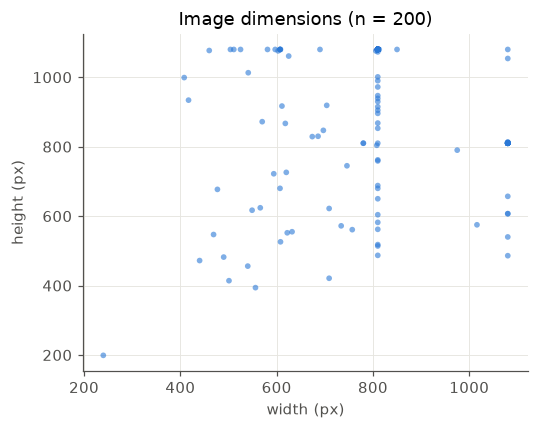

In [23]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(local.width, local.height, s=14, color=BLUE, alpha=0.6, edgecolors="none")
ax.set(title=f"Image dimensions (n = {len(local)})", xlabel="width (px)", ylabel="height (px)")
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_image_sizes.png"); plt.show()

## 7. Open decisions for Phase 2

These are choices the owner needs to approve before building the clean metadata CSV:

1. **Which 5–8 conditions** to keep (see section 3 and 5).
2. **Tied top labels**: drop tied cases, or keep them when both tied conditions are outside the chosen set?
3. **Label confidence**: require a minimum top weight (e.g. 0.5), or keep all untied cases?
4. **Skin-tone label**: eFST (dermatologist, more missing) vs Monk US vs Monk India as the primary grouping; and the grouping boundaries.
5. **eFST aggregation**: median of up to 3 dermatologists (used here) vs majority vote.
6. **Duplicates**: cases that share an image file (section 1) must be kept in the same split, or dropped.
7. **Contributor ID**: SCIN only has case IDs. One person could in principle have contributed more than once; this cannot be checked (and the license forbids re-identification), so it is a stated limitation.